# 01 数据探索与预处理方案 — Sen1Floods11

本 notebook 完成三件事：
1. **看清数据**：官方划分规模、事件分布、样例可视化（SAR 影像 + 标注）
2. **摸清坑**：NaN 像素、无效区、类别不平衡的定量统计（全文 446 对影像全量扫描）
3. **定预处理方案**：dB 裁剪范围、归一化公式、训练有效掩膜（双条件）

数据位置：`~/datasets/sen1floods11/`（下载脚本见 `scripts/download_sen1floods11.py`）

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile

DATA = Path.home() / "datasets/sen1floods11"
IMG_DIR = DATA / "data/flood_events/HandLabeled/S1Hand"
LAB_DIR = DATA / "data/flood_events/HandLabeled/LabelHand"
SPLIT_DIR = DATA / "splits/flood_handlabeled"
OUT_DIR = Path(__file__).resolve().parents[1] / "outputs" if "__file__" in dir() else Path("../outputs")
OUT_DIR.mkdir(exist_ok=True)

# 划分表没有表头：两列分别是 S1 影像文件名、标注文件名
splits = {
    name: pd.read_csv(SPLIT_DIR / f"flood_{name}_data.csv", header=None, names=["s1", "label"])
    for name in ["train", "valid", "test", "bolivia"]
}
print({k: len(v) for k, v in splits.items()})

{'train': 252, 'valid': 89, 'test': 90, 'bolivia': 15}


In [2]:
rows = []
for name, df in splits.items():
    events = df.s1.str.split("_").str[0].unique()
    rows.append({"split": name, "chips": len(df), "events": len(events), "event_names": ", ".join(events)})
overview = pd.DataFrame(rows)
overview

,split,chips,events,event_names
0,train,252,10,"Ghana, India, Mekong, Nigeria, Pakistan, Parag..."
1,valid,89,10,"Ghana, India, Mekong, Nigeria, Pakistan, Parag..."
2,test,90,10,"Ghana, India, Mekong, Nigeria, Pakistan, Parag..."
3,bolivia,15,1,Bolivia


## 样例可视化

SAR 影像存的是 dB 值（float32，含 NaN），直接看是黑的——需要按百分位拉伸到 0-255 才是人眼可看的灰度图。

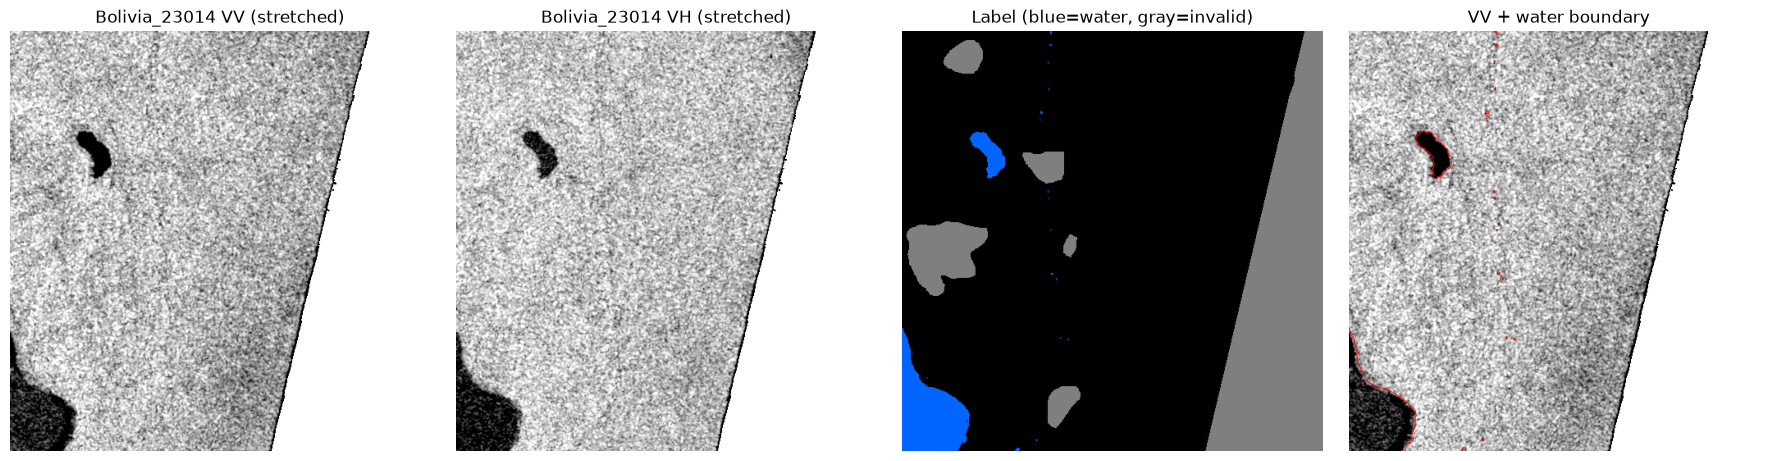

In [3]:
chip = "Bolivia_23014"
img = tifffile.imread(IMG_DIR / f"{chip}_S1Hand.tif").astype(np.float32)  # (2, 512, 512) = vv, vh
lab = tifffile.imread(LAB_DIR / f"{chip}_LabelHand.tif")  # (512, 512) int16

def stretch(band, p_lo=2, p_hi=98):
    """按有效像素的百分位拉伸到 [0,1]"""
    lo, hi = np.nanpercentile(band, [p_lo, p_hi])
    return np.clip((band - lo) / (hi - lo), 0, 1)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
axes[0].imshow(stretch(img[0]), cmap="gray"); axes[0].set_title(f"{chip} VV (stretched)")
axes[1].imshow(stretch(img[1]), cmap="gray"); axes[1].set_title(f"{chip} VH (stretched)")
rgb = np.zeros((*lab.shape, 3)); rgb[lab == 1] = [0, 0.4, 1]; rgb[lab == -1] = [0.5, 0.5, 0.5]
axes[2].imshow(rgb); axes[2].set_title("Label (blue=water, gray=invalid)")
axes[3].imshow(stretch(img[0]), cmap="gray")
axes[3].contour(lab == 1, colors="red", linewidths=0.6); axes[3].set_title("VV + water boundary")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

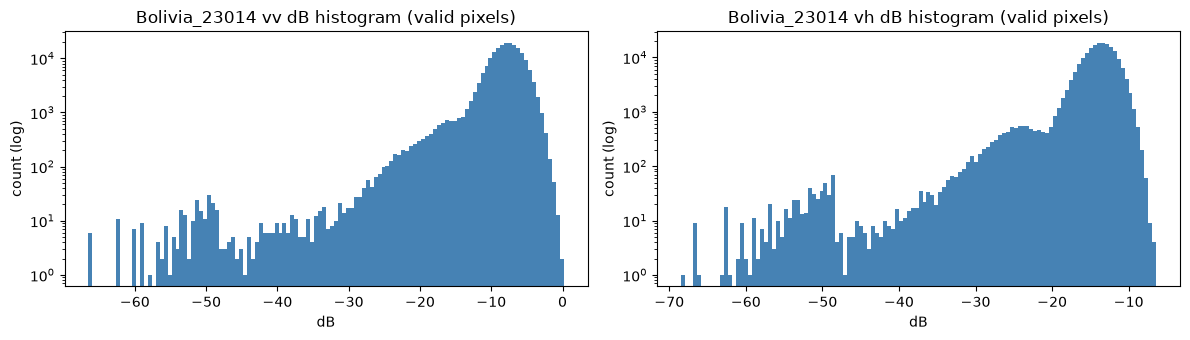

有效 dB 范围: vv [-66.5, 0.2], vh [-68.5, -6.4]


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, ch, name in zip(axes, img, ["vv", "vh"]):
    vals = ch[~np.isnan(ch)]
    ax.hist(vals, bins=120, color="steelblue", edgecolor="none")
    ax.set_yscale("log"); ax.set_title(f"{chip} {name} dB histogram (valid pixels)")
    ax.set_xlabel("dB"); ax.set_ylabel("count (log)")
plt.tight_layout(); plt.show()
print(f"有效 dB 范围: vv [{np.nanmin(img[0]):.1f}, {np.nanmax(img[0]):.1f}], vh [{np.nanmin(img[1]):.1f}, {np.nanmax(img[1]):.1f}]")

## 全量统计（446 对影像）

回答三个关键问题：
- 无效区（标注=-1）和 NaN（影像缺测）各占多少？**两者是否重合？**（决定掩膜怎么设计）
- 水体占比多少？（决定损失函数是否要处理类别不平衡）
- 全局 dB 的合理裁剪范围？（决定归一化参数）

In [5]:
records = []
for name, df in splits.items():
    for s1f, labf in zip(df.s1, df.label):
        im = tifffile.imread(IMG_DIR / s1f).astype(np.float32)
        lb = tifffile.imread(LAB_DIR / labf)
        nan_m = np.isnan(im).any(axis=0)
        inv_m = lb == -1
        dual_m = ~inv_m & ~nan_m  # 双条件有效掩膜
        rec = {
            "split": name, "chip": s1f,
            "water_pct": 100 * (lb == 1).mean(),
            "invalid_pct": 100 * inv_m.mean(),
            "nan_pct": 100 * nan_m.mean(),
            "dual_valid_pct": 100 * dual_m.mean(),
            # NaN 与无效区不一致的程度：在标注有效处出现 NaN，或标注有值处影像缺测
            "mismatch_pct": 100 * (inv_m ^ nan_m).mean(),
        }
        if dual_m.any():
            rec["vv_p1"], rec["vv_p99"] = np.nanpercentile(im[0][dual_m], [1, 99])
        records.append(rec)

stats = pd.DataFrame(records)
stats.to_csv(OUT_DIR / "data_summary.csv", index=False)
stats.groupby("split")[["water_pct", "invalid_pct", "nan_pct", "dual_valid_pct", "mismatch_pct"]].mean().round(2)

,water_pct,invalid_pct,nan_pct,dual_valid_pct,mismatch_pct
split,,,,,
bolivia,11.57,27.07,10.33,71.83,18.94
test,10.88,13.04,2.38,86.65,11.28
train,8.25,13.26,2.01,86.71,11.32
valid,9.59,13.01,0.94,86.90,12.25


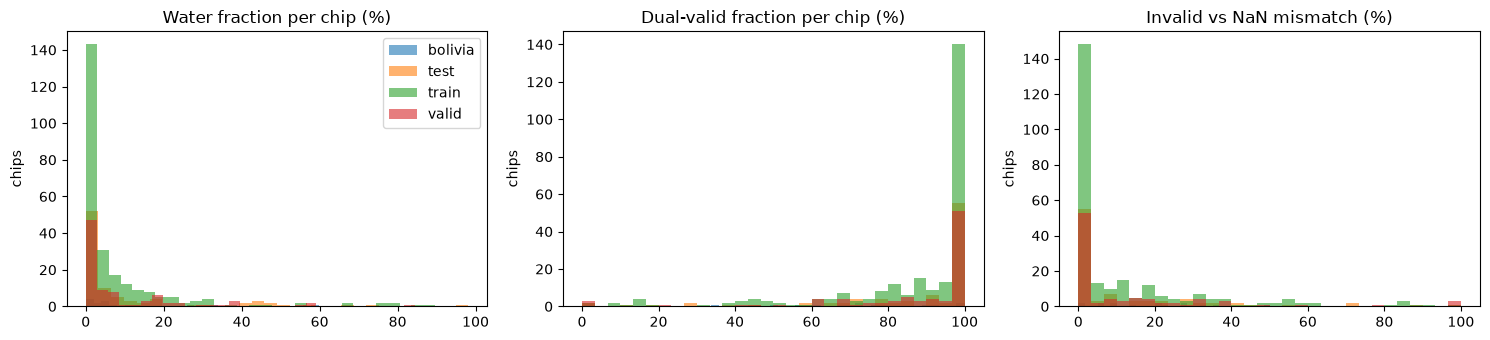

水体占比: 全体均值 9.2%, 中位数 2.2%, 最小 0.0%, 最大 98.1%
NaN与无效区不一致: 均值 11.8% 像素, 存在不一致的样本占 82%
双条件有效掩膜: 均值 86.2% 像素可用


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col, title in zip(
    axes,
    ["water_pct", "dual_valid_pct", "mismatch_pct"],
    ["Water fraction per chip (%)", "Dual-valid fraction per chip (%)", "Invalid vs NaN mismatch (%)"],
):
    for name, g in stats.groupby("split"):
        ax.hist(g[col], bins=30, alpha=0.6, label=name)
    ax.set_title(title); ax.set_ylabel("chips")
axes[0].legend()
plt.tight_layout(); plt.show()

print("水体占比: 全体均值 %.1f%%, 中位数 %.1f%%, 最小 %.1f%%, 最大 %.1f%%" % (
    stats.water_pct.mean(), stats.water_pct.median(), stats.water_pct.min(), stats.water_pct.max()))
print("NaN与无效区不一致: 均值 %.1f%% 像素, 存在不一致的样本占 %.0f%%" % (
    stats.mismatch_pct.mean(), 100 * (stats.mismatch_pct > 0).mean()))
print("双条件有效掩膜: 均值 %.1f%% 像素可用" % stats.dual_valid_pct.mean())

## 预处理方案定稿

用全体训练 chip 的 vv 通道 1%/99% 分位数的**中位数**作为全局裁剪范围（鲁棒、不受单张极端值影响），归一化到 [0,1]。

全局裁剪范围（train 中位数）: [-18.6, -4.3] dB


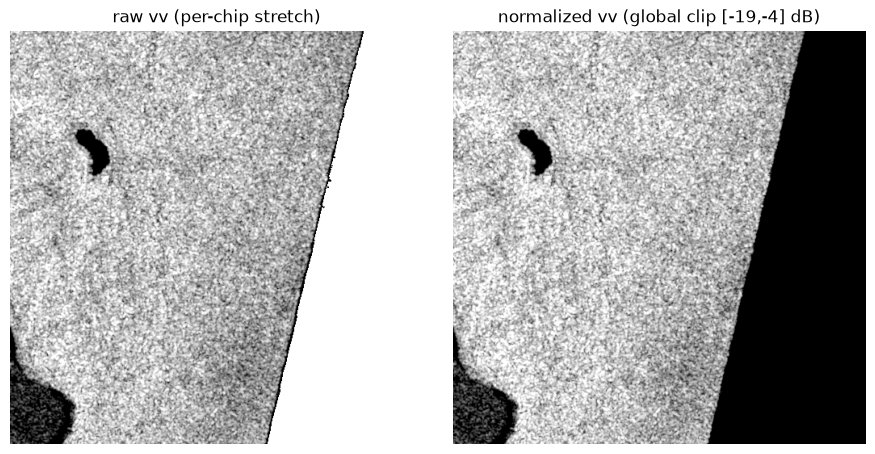

预处理参数已保存 -> outputs/preprocess_params.json


In [7]:
tr = stats[stats.split == "train"]
P1, P99 = tr.vv_p1.median(), tr.vv_p99.median()
print(f"全局裁剪范围（train 中位数）: [{P1:.1f}, {P99:.1f}] dB")

def normalize(im, p1=P1, p99=P99):
    """dB 裁剪 + 归一化到 [0,1]，NaN 置 0"""
    x = np.clip(im, p1, p99)
    x = (x - p1) / (p99 - p1)
    return np.nan_to_num(x, nan=0.0)

normed = normalize(img)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(stretch(img[0]), cmap="gray"); axes[0].set_title("raw vv (per-chip stretch)")
axes[1].imshow(normed[0], cmap="gray"); axes[1].set_title(f"normalized vv (global clip [{P1:.0f},{P99:.0f}] dB)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

# 保存预处理参数，供训练阶段直接加载
pd.Series({"clip_p1": P1, "clip_p99": P99}).to_json(OUT_DIR / "preprocess_params.json")
print("预处理参数已保存 -> outputs/preprocess_params.json")

## 结论（训练阶段直接引用）

1. **有效掩膜（关键）**：`valid = (label != -1) & ~isnan(image).any(channel)` —— NaN 与标注无效区**互不完全包含**（不一致像素均值见上），只排除一边都会把脏数据喂进损失函数
2. **类别不平衡**：水体占比很低（见上方统计），损失用 BCE + Dice 组合（Dice 对不平衡天然稳健）
3. **归一化**：全局 dB 裁剪范围取 train 集分位数中位数（已存 `outputs/preprocess_params.json`），NaN 归一化前置 0
4. **数据划分**：严格用官方 split（train 252 / valid 89 / test 90 / bolivia 15），Bolivia 作为分布外事件留作泛化分析